# Linear SVC (Linear Support Vector Classifier)

Follows a 13-section workflow to train, evaluate, compare, and export a linear SVM using 46 features.

In [1]:

# 1. Setup - Imports and random seed
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.svm import LinearSVC, SVC
import joblib
np.random.seed(42)
print('Libraries loaded')


Libraries loaded


Class balance (train):
label
human      2678
nothing    1836
Name: count, dtype: int64
Class balance (test):
label
human      141
nothing     97
Name: count, dtype: int64


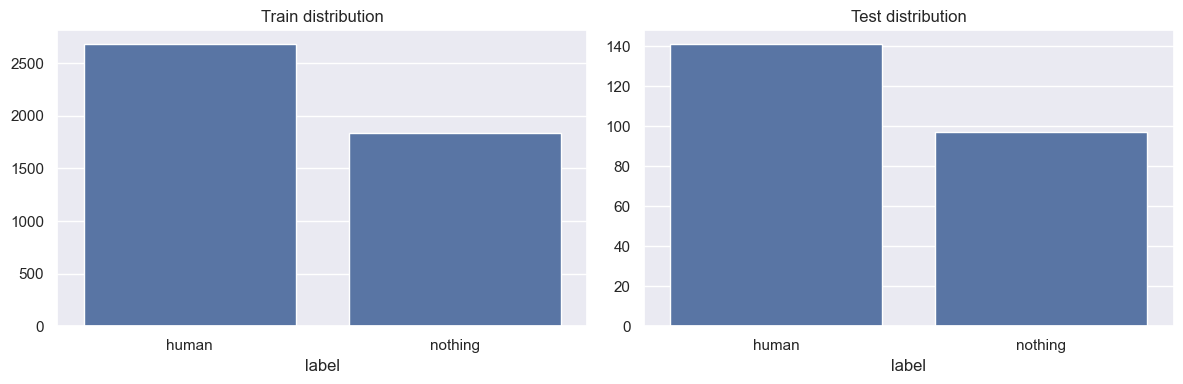

In [3]:

# 2. Data Loading - Load CSV, visualize distribution
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
TRAIN_PATH = os.path.join('..','datasets','training_data_noise_clamp_train.csv')
TEST_PATH = os.path.join('..','datasets','training_data_noise_clamp_test.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError(f"Train/Test datasets not found: {TRAIN_PATH}, {TEST_PATH}")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns, build_feature_matrix
schema = detect_feature_columns(df_train)
label_col = schema['label_col']
if not label_col:
    raise ValueError('No label column detected. Expected one of: label/class/target')
class_counts_train = df_train[label_col].value_counts()
class_counts_test = df_test[label_col].value_counts()
print('Class balance (train):')
print(class_counts_train)
print('Class balance (test):')
print(class_counts_test)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); sns.barplot(x=class_counts_train.index, y=class_counts_train.values); plt.title('Train distribution')
plt.subplot(1,2,2); sns.barplot(x=class_counts_test.index, y=class_counts_test.values); plt.title('Test distribution')
plt.tight_layout(); plt.show()


Features selected: 46
Sample features: ['move0', 'move1', 'move2', 'move3', 'move4', 'move5', 'move6', 'move7', 'move8', 'move9']


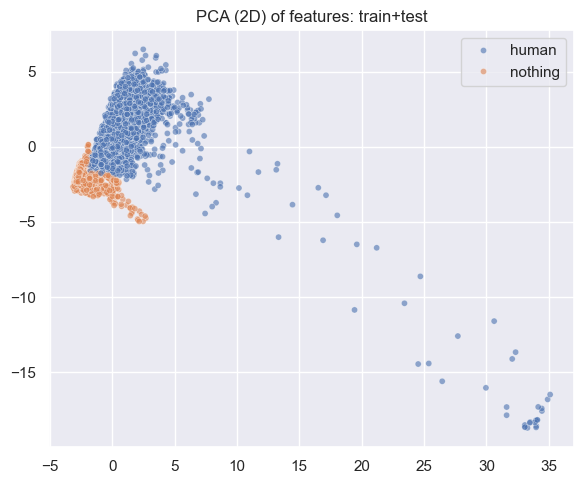

In [4]:

# 3. Features - Define 46 features, clean data
feature_cols = list(schema['classic_feature_cols'])
exclude = set(['label','class','target','session_id','session','recording_id','recording','seq_id','timestep','timestamp','frame','time'])
numeric_cols = df_train.select_dtypes(include=['number']).columns.tolist()
fallback_cols = [c for c in numeric_cols if c not in exclude and c not in feature_cols]
if len(feature_cols) < 46:
    need = 46 - len(feature_cols)
    feature_cols += fallback_cols[:need]
elif len(feature_cols) > 46:
    feature_cols = feature_cols[:46]
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
# Clean: fill NaN with column medians (fit on train)
train_df = pd.DataFrame(X_train_all, columns=feature_cols)
test_df = pd.DataFrame(X_test_all, columns=feature_cols)
train_df = train_df.fillna(train_df.median(numeric_only=True))
medians = train_df.median(numeric_only=True)
test_df = test_df.fillna(medians)
X_train_all = train_df.values
X_test_all = test_df.values
print('Features selected:', len(feature_cols))
print('Sample features:', feature_cols[:10])
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
X_vis = StandardScaler().fit_transform(np.vstack([X_train_all, X_test_all]))
y_vis = np.concatenate([y_str_train, y_str_test])
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_vis)
plt.figure(figsize=(6,5))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y_vis, alpha=0.6, s=20)
plt.title('PCA (2D) of features: train+test')
plt.tight_layout(); plt.show()


In [6]:

# 4. Split - Encode labels, use pre-split train/test, scale features
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_all)
X_test_scaled = scaler.transform(X_test_all)
print('Train shape:', X_train_all.shape, 'Test shape:', X_test_all.shape)
print('Classes:', list(le.classes_))


Train shape: (4514, 46) Test shape: (238, 46)
Classes: ['human', 'nothing']


In [16]:

# 5. Train - Fit LinearSVC
lin_svc = LinearSVC(C=0.01, loss='squared_hinge', penalty='l2', dual=False, max_iter=5000, random_state=42)
t0 = time.time()
lin_svc.fit(X_train_scaled, y_train)
train_time_linear = time.time() - t0
print('Trained LinearSVC in', round(train_time_linear, 4), 's')


Trained LinearSVC in 0.0548 s


In [17]:

# 6. Evaluate - Accuracy, classification report
y_pred = lin_svc.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print('Test accuracy:', round(acc, 4))
print('Classification report:', classification_report(y_test, y_pred, target_names=list(le.classes_)))


Test accuracy: 1.0
Classification report:               precision    recall  f1-score   support

       human       1.00      1.00      1.00       141
     nothing       1.00      1.00      1.00        97

    accuracy                           1.00       238
   macro avg       1.00      1.00      1.00       238
weighted avg       1.00      1.00      1.00       238



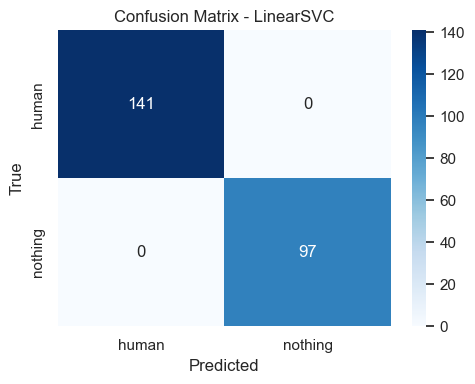

In [18]:

# 7. Confusion Matrix - Visualize mistakes
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Confusion Matrix - LinearSVC')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()


In [19]:

# 8. Feature Importance - Coefficient weights
coef = lin_svc.coef_  # shape (n_classes, n_features) for OvR
importance = np.linalg.norm(coef, axis=0)
top_idx = np.argsort(importance)[::-1][:10]
top_features = [(feature_cols[i], float(importance[i])) for i in top_idx]
print('Top features (by weight magnitude):')
for name, weight in top_features:
    print(f'{name}: {weight:.4f}')


Top features (by weight magnitude):
move_variance: 0.6506
move12: 0.3082
stat_centroid: 0.2192
stat_spread: 0.1253
motion_duration: 0.1248
move_centroid: 0.1042
max_stat_energy: 0.0911
active_stat_zones: 0.0901
stat10: 0.0899
stat11: 0.0857


In [20]:

# 9. Hyperparameter Tuning - Try different C values
C_values = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for C in C_values:
    model = LinearSVC(C=C, loss='squared_hinge', penalty='l2', dual=False, max_iter=5000, random_state=42)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, n_jobs=-1)
    cv_scores[C] = float(np.mean(scores))
best_C = max(cv_scores, key=cv_scores.get)
print('CV scores:', cv_scores)
print('Best C found:', best_C)
# Retrain with best C
lin_svc = LinearSVC(C=best_C, loss='squared_hinge', penalty='l2', dual=False, max_iter=5000, random_state=42)
lin_svc.fit(X_train_scaled, y_train)
y_pred = lin_svc.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print('Test accuracy (best C):', round(acc, 4))


CV scores: {1e-05: 0.9388539802039517, 0.0001: 0.9893660697404316, 0.001: 0.9997782705099778, 0.01: 1.0, 0.1: 1.0, 1.0: 1.0, 10.0: 1.0}
Best C found: 0.01
Test accuracy (best C): 1.0


In [21]:

# 10. Comparison - LinearSVC vs SVC speed
t0 = time.time()
svc_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svc_rbf.fit(X_train_scaled, y_train)
train_time_svc = time.time() - t0
t1 = time.time(); _ = svc_rbf.predict(X_test_scaled); pred_time_svc = time.time() - t1
t2 = time.time(); _ = lin_svc.predict(X_test_scaled); pred_time_linear = time.time() - t2
print('Train time LinearSVC:', round(train_time_linear, 4), 's')
print('Train time SVC (RBF):', round(train_time_svc, 4), 's')
print('Predict time LinearSVC:', round(pred_time_linear, 4), 's')
print('Predict time SVC (RBF):', round(pred_time_svc, 4), 's')


Train time LinearSVC: 0.0548 s
Train time SVC (RBF): 0.1822 s
Predict time LinearSVC: 0.0107 s
Predict time SVC (RBF): 0.0189 s


In [22]:

# 11. Save - Export model and metadata
os.makedirs(os.path.join('..','models'), exist_ok=True)
model_path = os.path.join('..','models','LinearSVC.pkl')
meta_path = os.path.join('..','models','LinearSVC_meta.json')
joblib.dump({'model': lin_svc, 'scaler': scaler, 'label_encoder': le, 'feature_cols': feature_cols}, model_path)
meta = {
    'algorithm': 'LinearSVC',
    'best_C': float(best_C),
    'test_accuracy': float(acc),
    'features_used': feature_cols,
    'num_features': int(len(feature_cols)),
    'classes': list(le.classes_),
}
import json
with open(meta_path, 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved', model_path, 'and', meta_path)


Saved ../models/LinearSVC.pkl and ../models/LinearSVC_meta.json


In [23]:

# 12. Test Predictions - Show sample results
sample_idx = np.arange(min(10, len(X_test_scaled)))
sample_preds = lin_svc.predict(X_test_scaled[sample_idx])
sample_true = y_test[sample_idx]
df_samples = pd.DataFrame({
    'true': le.inverse_transform(sample_true),
    'pred': le.inverse_transform(sample_preds)
})
print(df_samples)


      true     pred
0  nothing  nothing
1  nothing  nothing
2    human    human
3    human    human
4  nothing  nothing
5    human    human
6  nothing  nothing
7  nothing  nothing
8  nothing  nothing
9    human    human


In [24]:

# 13. Summary - Final statistics
print('Summary:')
print('Best C:', best_C)
print('Test accuracy:', round(acc, 4))


Summary:
Best C: 0.01
Test accuracy: 1.0


In [25]:

# 14. External Evaluate - nothing_indoor2.csv
import os, numpy as np, pandas as pd
NEW_PATH = os.path.join('..','datasets','nothing_indoor2.csv')
print('Evaluating external dataset:', NEW_PATH)
if os.path.exists(NEW_PATH):
    df_new = pd.read_csv(NEW_PATH)
    # Feature columns from training
    feature_cols = feature_cols if 'feature_cols' in locals() else [f'f{i}' for i in range(1,47)]
    X_new = df_new[feature_cols].values
    X_new_scaled = scaler.transform(X_new) if 'scaler' in locals() else X_new
    # Predictions
    y_pred_new = lin_svc.predict(X_new_scaled)
    # Decision margins and softmax probs
    margins_new = lin_svc.decision_function(X_new_scaled)
    def softmax(m):
        m = np.array(m, dtype=np.float32)
        m = m - m.max(axis=1, keepdims=True)
        e = np.exp(m)
        return e / e.sum(axis=1, keepdims=True)
    probs_new = softmax(margins_new)
    # Metrics (requires label encoder)
    try:
        y_true_new = le.transform(df_new['label'].astype(str).values)
        from sklearn.metrics import accuracy_score, classification_report
        acc_new = accuracy_score(y_true_new, y_pred_new)
        print('Rows:', len(df_new))
        print('Accuracy:', round(acc_new, 4))
        print(classification_report(le.inverse_transform(y_true_new), le.inverse_transform(y_pred_new)))
    except Exception as e:
        print('Note: could not compute accuracy with label encoder:', e)
    # Probability summary
    classes = list(le.classes_) if 'le' in locals() else [str(i) for i in range(margins_new.shape[1])]
    mean_probs = probs_new.mean(axis=0)
    print('Mean class probabilities:', {c: round(p,4) for c,p in zip(classes, mean_probs)})
    # Show first 10 rows
    nshow = min(10, len(df_new))
    preds_names = le.inverse_transform(y_pred_new) if 'le' in locals() else y_pred_new
    print(pd.DataFrame({
        'true': df_new['label'].astype(str).head(nshow),
        'pred': preds_names[:nshow]
    }))
else:
    print('File not found:', NEW_PATH)


Evaluating external dataset: ../datasets/nothing_indoor2.csv


KeyError: "None of [Index(['move0', 'move1', 'move2', 'move3', 'move4', 'move5', 'move6', 'move7',\n       'move8', 'move9', 'move10', 'move11', 'move12', 'move13',\n       'max_move_energy', 'total_move_energy', 'active_move_zones',\n       'move_centroid', 'move_spread', 'move_change_rate', 'motion_duration',\n       'move_variance', 'max_stat_energy', 'total_stat_energy',\n       'active_stat_zones', 'stat_centroid', 'stat_spread', 'stat_change_rate',\n       'stat_variance', 'zone_switches', 'zones_sequential',\n       'zone_correlation', 'stat0', 'stat1', 'stat2', 'stat3', 'stat4',\n       'stat5', 'stat6', 'stat7', 'stat8', 'stat9', 'stat10', 'stat11',\n       'stat12', 'stat13'],\n      dtype='object')] are in the [columns]"